<a href="https://colab.research.google.com/github/Rubin-S/nifty50-sma-backtester/blob/main/Institutional_Execution_Microstructure_%26_Statistical_Validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantitative Strategy: Institutional Execution Microstructure & Statistical Validation
## Module 1: Historical Ingestion & Return Decomposition (Gap vs. Intraday)

### Objective
Ingest NIFTY 50 data and decouple daily price returns into overnight opening gaps and intraday trading sessions to accurately model Next-Bar Open ($t+1$) order execution:

* **Overnight Gap Return:** $R_{\text{gap}, t} = \frac{\text{Open}_t - \text{Close}_{t-1}}{\text{Close}_{t-1}}$
* **Intraday Session Return:** $R_{\text{intraday}, t} = \frac{\text{Close}_t - \text{Open}_t}{\text{Open}_t}$
* **Standard Close-to-Close Return:** $R_{\text{market}, t} = \frac{\text{Close}_t - \text{Close}_{t-1}}{\text{Close}_{t-1}}$

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# 1. Download NIFTY 50 historical OHLC data
ticker = "^NSEI"
df = yf.download(ticker, start="2018-01-01", end="2026-01-01", auto_adjust=True)
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# 2. Return Decomposition
# Overnight Gap: Prior Close (3:30 PM) -> Current Open (9:15 AM)
df['Gap_Return'] = (df['Open'] - df['Close'].shift(1)) / df['Close'].shift(1)

# Intraday Return: Current Open (9:15 AM) -> Current Close (3:30 PM)
df['Intraday_Return'] = (df['Close'] - df['Open']) / df['Open']

# Standard Close-to-Close Return: Prior Close -> Current Close
df['Market_Return'] = df['Close'].pct_change().fillna(0.0)

# 3. Clean initial NaN values
df.fillna(0.0, inplace=True)

# 4. Preview engineered return streams
df[['Open', 'Close', 'Gap_Return', 'Intraday_Return', 'Market_Return']].head()

[*********************100%***********************]  1 of 1 completed


Price,Open,Close,Gap_Return,Intraday_Return,Market_Return
Date,,,,,
2018-01-02,10477.549805,10442.200195,0.000000,-0.003374,0.000000
2018-01-03,10482.650391,10443.200195,0.003874,-0.003763,0.000096
2018-01-04,10469.400391,10504.799805,0.002509,0.003381,0.005899
2018-01-05,10534.250000,10558.849609,0.002803,0.002335,0.005145
2018-01-08,10591.700195,10623.599609,0.003111,0.003012,0.006132


## Module 2: Indicator Construction (Dual SMA & Adaptive ATR)

### Objective
Compute trend-following moving averages and 14-day Average True Range (ATR) to establish volatility-adjusted trailing stop levels:

* **Fast SMA (10-day) & Slow SMA (70-day)**
* **True Range ($TR_t$):** $\max(\text{High}_t - \text{Low}_t, \, |\text{High}_t - \text{Close}_{t-1}|, \, |\text{Low}_t - \text{Close}_{t-1}|)$
* **ATR-14:** 14-day rolling mean of $TR_t$

In [2]:
# 1. Trend Indicators (10/70 Moving Averages)
df['SMA_Fast'] = df['Close'].rolling(window=10).mean()
df['SMA_Slow'] = df['Close'].rolling(window=70).mean()

# 2. Average True Range (ATR-14)
high_low = df['High'] - df['Low']
high_prev_close = (df['High'] - df['Close'].shift(1)).abs()
low_prev_close = (df['Low'] - df['Close'].shift(1)).abs()

df['TR'] = pd.concat([high_low, high_prev_close, low_prev_close], axis=1).max(axis=1)
df['ATR'] = df['TR'].rolling(window=14).mean()

# 3. Clean initial rolling NaNs
df.dropna(inplace=True)

# 4. Preview indicator values
df[['Close', 'SMA_Fast', 'SMA_Slow', 'TR', 'ATR']].head()

Price,Close,SMA_Fast,SMA_Slow,TR,ATR
Date,,,,,
2018-04-16,10528.349609,10369.650000,10499.812891,143.800781,103.275112
2018-04-17,10548.700195,10400.020020,10501.334319,64.799805,94.692941
2018-04-18,10526.200195,10439.800000,10502.520033,84.500000,95.210798
2018-04-19,10565.299805,10463.814941,10503.384319,46.000000,92.264369
2018-04-20,10564.049805,10487.059961,10503.458608,54.899414,88.585798


## Module 3: Next-Bar Open State Machine & Microstructure Execution

### Objective
Implement a sequential state machine in NumPy to track trade states, update ratcheting ATR stop floors, and assign exact Next-Bar Open ($t+1$) return profiles:

* **Entry Day ($0 \rightarrow 1$):** Captures $R_{\text{intraday}, t} = \frac{\text{Close}_t - \text{Open}_t}{\text{Open}_t}$
* **Holding Day ($1 \rightarrow 1$):** Captures $R_{\text{market}, t} = \frac{\text{Close}_t - \text{Close}_{t-1}}{\text{Close}_{t-1}}$
* **Exit Day ($1 \rightarrow 0$):** Captures $R_{\text{gap}, t} = \frac{\text{Open}_t - \text{Close}_{t-1}}{\text{Close}_{t-1}}$
* **Cash Day ($0 \rightarrow 0$):** Pure cash holding ($0.0\%$)

In [3]:
# 1. Extract raw NumPy arrays for high-speed sequential execution
close = df['Close'].values
open_p = df['Open'].values
sma_fast = df['SMA_Fast'].values
sma_slow = df['SMA_Slow'].values
atr = df['ATR'].values

gap_ret = df['Gap_Return'].values
intra_ret = df['Intraday_Return'].values
mkt_ret = df['Market_Return'].values

n = len(df)

# 2. State & Return tracking arrays
raw_signals = np.zeros(n)      # Signal generated at Close t
stop_levels = np.zeros(n)      # Active ratcheting trailing stop
strat_gross_ret = np.zeros(n)  # Strategy gross returns with open execution

# 3. State Machine Parameters
state = 0            # 0 = Cash, 1 = Long
current_stop = 0.0
atr_multiplier = 3.0

# 4. Sequential Loop (Starting after 70-day indicator warmup)
for i in range(70, n):
    # Determine yesterday's generated signal
    prev_sig = raw_signals[i-1]

    # -------------------------------------------------------------
    # Step A: Realize Execution on Day i based on Signal at Close i-1
    # -------------------------------------------------------------
    if prev_sig == 1.0 and state == 0:
        # State 0 -> 1: Entry Day (Enter at Open, hold to Close)
        strat_gross_ret[i] = intra_ret[i]
        state = 1
    elif prev_sig == 1.0 and state == 1:
        # State 1 -> 1: Holding Day (Hold Close-to-Close)
        strat_gross_ret[i] = mkt_ret[i]
    elif prev_sig == 0.0 and state == 1:
        # State 1 -> 0: Exit Day (Hold overnight, exit at Open)
        strat_gross_ret[i] = gap_ret[i]
        state = 0
    elif prev_sig == 0.0 and state == 0:
        # State 0 -> 0: Cash Day
        strat_gross_ret[i] = 0.0

    # -------------------------------------------------------------
    # Step B: Calculate New Signal at Close of Day i
    # -------------------------------------------------------------
    if state == 0:
        # Check for fresh Golden Crossover
        if sma_fast[i] > sma_slow[i] and sma_fast[i-1] <= sma_slow[i-1]:
            raw_signals[i] = 1.0
            current_stop = close[i] - (atr_multiplier * atr[i])
            stop_levels[i] = current_stop
        else:
            raw_signals[i] = 0.0
            stop_levels[i] = 0.0
            current_stop = 0.0

    elif state == 1:
        # Update ratcheting stop floor
        candidate_stop = close[i] - (atr_multiplier * atr[i])
        current_stop = max(current_stop, candidate_stop)
        stop_levels[i] = current_stop

        # Check exit triggers (Stop hit OR Death Cross)
        if close[i] <= current_stop or sma_fast[i] <= sma_slow[i]:
            raw_signals[i] = 0.0
            current_stop = 0.0
        else:
            raw_signals[i] = 1.0

# 5. Attach engineered series to DataFrame
df['Raw_Signal'] = raw_signals
df['Stop_Level'] = stop_levels
df['Gross_Return'] = strat_gross_ret

# 6. Preview state machine behavior
df[['Close', 'SMA_Fast', 'SMA_Slow', 'Stop_Level', 'Raw_Signal', 'Gross_Return']].tail(10)

Price,Close,SMA_Fast,SMA_Slow,Stop_Level,Raw_Signal,Gross_Return
Date,,,,,,
2025-12-17,25818.550781,25942.985156,25576.360798,25609.569894,1.0,-0.001607
2025-12-18,25815.550781,25921.165234,25591.252232,25609.569894,1.0,-0.000116
2025-12-19,25966.400391,25899.160352,25606.935100,25609.569894,1.0,0.005843
2025-12-22,26172.400391,25920.345313,25624.067969,25609.569894,1.0,0.007933
2025-12-23,26177.150391,25954.095313,25640.805831,25609.569894,1.0,0.000181
2025-12-24,26142.099609,25992.505273,25655.492969,25609.569894,1.0,-0.001339
2025-12-26,26042.300781,26006.880273,25669.394420,25609.569894,1.0,-0.003818
2025-12-29,25942.099609,25996.395313,25679.437277,25609.569894,1.0,-0.003848
2025-12-30,25938.849609,25987.550195,25688.131557,25609.569894,1.0,-0.000125


## Module 4: Integrated Total Return & Sizing Engine

### Objective
Integrate Next-Bar Open execution gross returns ($R_{\text{gross}, t}$) with continuous balance-sheet accounting, dynamic volatility budgeting, and turnover friction:

* **Benchmark TRI:** Captures Close-to-Close market returns plus daily dividends ($d_{\text{yield}} = 1.3\%$).
* **Strategy Total Return:** Invested equity with dividends, liquid yield on unallocated margin ($r_f = 6.5\%$), minus proportional transaction costs (5 bps):

$$R_{\text{strategy}, t} = \left(w_t \times (R_{\text{gross}, t} + d_{\text{daily}})\right) + \left((1 - w_t) \times r_{\text{daily}}\right) - (\text{Trades}_t \times \text{Cost})$$

In [4]:
# 1. Total Return Baseline Constants
rf_annual = 0.065          # 6.5% Liquid / TREPS yield
div_yield_annual = 0.013   # 1.3% NIFTY 50 dividend yield
fee_bps = 5
cost_per_trade = fee_bps / 10000.0

rf_daily = rf_annual / 252.0
div_daily = div_yield_annual / 252.0

# 2. Dynamic Volatility Targeting (12% Target Volatility)
target_vol = 0.12
max_leverage = 1.0
df['Realized_Vol'] = df['Market_Return'].ewm(span=20).std() * np.sqrt(252)
df['Capped_Weight'] = (target_vol / df['Realized_Vol']).clip(upper=max_leverage)

# 3. Dynamic Position Sizing with 5% Rebalance Buffer
target_pos = (df['Raw_Signal'] * df['Capped_Weight']).values
raw_sig = df['Raw_Signal'].values
buffered_pos = np.zeros(len(df))
buffer_threshold = 0.05

current_pos = 0.0
for i in range(len(df)):
    if raw_sig[i] == 0.0:
        current_pos = 0.0
    elif abs(target_pos[i] - current_pos) >= buffer_threshold:
        current_pos = target_pos[i]
    buffered_pos[i] = current_pos

# Executed weight at day t
df['Weight'] = buffered_pos
df['Trades'] = df['Weight'].diff().abs().fillna(0.0)
df['Cash_Weight'] = 1.0 - df['Weight']

# 4. Total Return Calculations
df['Benchmark_Return'] = df['Market_Return'] + div_daily
df['Strategy_Return'] = (
    (df['Weight'] * (df['Gross_Return'] + div_daily))
    + (df['Cash_Weight'] * rf_daily)
    - (df['Trades'] * cost_per_trade)
)

# 5. Compound Cumulative Equity Curves
df['Benchmark_Equity'] = (1 + df['Benchmark_Return']).cumprod()
df['Strategy_Equity'] = (1 + df['Strategy_Return']).cumprod()

# 6. Preview latest returns and asset weights
df[['Close', 'Gross_Return', 'Weight', 'Cash_Weight', 'Strategy_Return', 'Strategy_Equity']].tail()

Price,Close,Gross_Return,Weight,Cash_Weight,Strategy_Return,Strategy_Equity
Date,,,,,,
2025-12-24,26142.099609,-0.001339,1.0,0.0,-0.001287,2.692894
2025-12-26,26042.300781,-0.003818,1.0,0.0,-0.003766,2.682753
2025-12-29,25942.099609,-0.003848,1.0,0.0,-0.003796,2.672569
2025-12-30,25938.849609,-0.000125,1.0,0.0,-0.000074,2.672372
2025-12-31,26129.599609,0.007354,1.0,0.0,0.007405,2.692162


## Module 5: Performance Attribution & Statistical Hypothesis Testing

### Objective
Evaluate risk-adjusted performance using conventional arithmetic Sharpe metrics and test whether the observed Sharpe ratio statistically clears zero noise using Lo (2002) asymptotic standard errors:

* **Textbook Sharpe:** $\frac{\mu(R_t - r_{f,t})}{\sigma(R_t - r_{f,t})} \times \sqrt{252}$
* **Standard Error (Lo, 2002):** $\text{SE}(\widehat{\text{SR}}) = \sqrt{\frac{1 + 0.5\widehat{\text{SR}}^2}{T}}$
* **$t$-statistic:** $t = \frac{\widehat{\text{SR}}}{\text{SE}}$

In [5]:
from scipy.stats import norm

# 1. Horizon setup
trading_days = 252
n_days = len(df)
t_years = n_days / trading_days

# 2. Daily Excess Returns
df['Strategy_Excess'] = df['Strategy_Return'] - rf_daily
df['Benchmark_Excess'] = df['Benchmark_Return'] - rf_daily

# 3. Geometric CAGR
cagr_strat = (df['Strategy_Equity'].iloc[-1]) ** (trading_days / n_days) - 1
cagr_bench = (df['Benchmark_Equity'].iloc[-1]) ** (trading_days / n_days) - 1

# 4. Annualized Volatility
vol_strat = df['Strategy_Return'].std() * np.sqrt(trading_days)
vol_bench = df['Benchmark_Return'].std() * np.sqrt(trading_days)

# 5. Conventional Textbook Annualized Sharpe Ratio
sharpe_strat = (df['Strategy_Excess'].mean() / df['Strategy_Excess'].std()) * np.sqrt(trading_days)
sharpe_bench = (df['Benchmark_Excess'].mean() / df['Benchmark_Excess'].std()) * np.sqrt(trading_days)

# 6. Lo (2002) Standard Error & t-statistic
se_strat = np.sqrt((1 + 0.5 * (sharpe_strat ** 2)) / t_years)
t_stat_strat = sharpe_strat / se_strat
p_value_strat = 1 - norm.cdf(t_stat_strat)

# 7. Maximum Drawdown (MDD)
strat_peak = df['Strategy_Equity'].cummax()
strat_dd = (df['Strategy_Equity'] - strat_peak) / strat_peak
mdd_strat = strat_dd.min()

bench_peak = df['Benchmark_Equity'].cummax()
bench_dd = (df['Benchmark_Equity'] - bench_peak) / bench_peak
mdd_bench = bench_dd.min()

# 8. Statistical Performance Report
print("=== Quantitative Performance & Statistical Significance Report ===")
print(f"Sample Horizon:            {n_days} sessions ({t_years:.2f} years)")
print(f"Strategy CAGR:             {cagr_strat * 100:.2f}% | Benchmark TRI: {cagr_bench * 100:.2f}%")
print(f"Annualized Volatility:     {vol_strat * 100:.2f}%  | Benchmark TRI: {vol_bench * 100:.2f}%")
print(f"Textbook Sharpe Ratio:     {sharpe_strat:.2f}   | Benchmark TRI: {sharpe_bench:.2f}")
print(f"Sharpe Standard Error:     {se_strat:.3f}")
print(f"t-statistic:               {t_stat_strat:.3f}")
print(f"p-value (H0: SR <= 0):     {p_value_strat:.4f}")
print(f"Max Drawdown (MDD):        {mdd_strat * 100:.2f}%  | Benchmark TRI: {mdd_bench * 100:.2f}%")

=== Quantitative Performance & Statistical Significance Report ===
Sample Horizon:            1903 sessions (7.55 years)
Strategy CAGR:             14.01% | Benchmark TRI: 14.34%
Annualized Volatility:     5.46%  | Benchmark TRI: 17.19%
Textbook Sharpe Ratio:     1.24   | Benchmark TRI: 0.49
Sharpe Standard Error:     0.484
t-statistic:               2.561
p-value (H0: SR <= 0):     0.0052
Max Drawdown (MDD):        -3.12%  | Benchmark TRI: -38.29%


## Module 6: Out-of-Sample Parameter Neighborhood Stability

### Objective
Evaluate the 8 parameter neighbors adjacent to our $(10, 70)$ configuration on unseen Out-of-Sample data (2024–2026) to verify that performance forms a stable plateau rather than an isolated overfit spike:

* **Fast Moving Average Range:** $[9, 10, 11]$
* **Slow Moving Average Range:** $[65, 70, 75]$
* **Execution Framework:** Next-Bar Open execution ($t+1$), ATR ratcheting stops, dynamic volatility targeting, and continuous cash yield.

In [6]:
# 1. Define evaluation function for arbitrary Fast/Slow on any dataset slice
def run_full_pipeline(data_slice, fast_p, slow_p, atr_mult=3.0, target_v=0.12, rf_ann=0.065, div_ann=0.013, fee_b=5):
    sub = data_slice.copy()

    # Technical Indicators
    sub['SMA_Fast'] = sub['Close'].rolling(window=fast_p).mean()
    sub['SMA_Slow'] = sub['Close'].rolling(window=slow_p).mean()

    h_l = sub['High'] - sub['Low']
    h_pc = (sub['High'] - sub['Close'].shift(1)).abs()
    l_pc = (sub['Low'] - sub['Close'].shift(1)).abs()
    sub['TR'] = pd.concat([h_l, h_pc, l_pc], axis=1).max(axis=1)
    sub['ATR'] = sub['TR'].rolling(window=14).mean()

    # Realized Volatility for Sizing
    sub['Realized_Vol'] = sub['Market_Return'].ewm(span=20).std() * np.sqrt(252)
    sub['Capped_Weight'] = (target_v / sub['Realized_Vol']).clip(upper=1.0)

    c_arr = sub['Close'].values
    sf_arr = sub['SMA_Fast'].values
    ss_arr = sub['SMA_Slow'].values
    atr_arr = sub['ATR'].values
    gap_a = sub['Gap_Return'].values
    intra_a = sub['Intraday_Return'].values
    mkt_a = sub['Market_Return'].values

    n_len = len(sub)
    r_sigs = np.zeros(n_len)
    g_rets = np.zeros(n_len)

    st = 0
    c_stop = 0.0

    # State Machine with Next-Bar Open Fill
    for j in range(slow_p, n_len):
        p_sig = r_sigs[j-1]

        # Realize Day j execution
        if p_sig == 1.0 and st == 0:
            g_rets[j] = intra_a[j]
            st = 1
        elif p_sig == 1.0 and st == 1:
            g_rets[j] = mkt_a[j]
        elif p_sig == 0.0 and st == 1:
            g_rets[j] = gap_a[j]
            st = 0
        elif p_sig == 0.0 and st == 0:
            g_rets[j] = 0.0

        # Signal Generation at Close j
        if st == 0:
            if sf_arr[j] > ss_arr[j] and sf_arr[j-1] <= ss_arr[j-1]:
                r_sigs[j] = 1.0
                c_stop = c_arr[j] - (atr_mult * atr_arr[j])
            else:
                r_sigs[j] = 0.0
                c_stop = 0.0
        elif st == 1:
            c_stop = max(c_stop, c_arr[j] - (atr_mult * atr_arr[j]))
            if c_arr[j] <= c_stop or sf_arr[j] <= ss_arr[j]:
                r_sigs[j] = 0.0
                c_stop = 0.0
            else:
                r_sigs[j] = 1.0

    sub['Raw_Signal'] = r_sigs
    sub['Gross_Return'] = g_rets

    # Tolerance Band & Sizing
    t_pos = (sub['Raw_Signal'] * sub['Capped_Weight']).values
    r_sig_vals = sub['Raw_Signal'].values
    b_pos = np.zeros(n_len)
    cur_p = 0.0
    for j in range(n_len):
        if r_sig_vals[j] == 0.0:
            cur_p = 0.0
        elif abs(t_pos[j] - cur_p) >= 0.05:
            cur_p = t_pos[j]
        b_pos[j] = cur_p

    sub['Weight'] = b_pos
    sub['Trades'] = sub['Weight'].diff().abs().fillna(0.0)
    sub['Cash_Weight'] = 1.0 - sub['Weight']

    rf_d = rf_ann / 252.0
    div_d = div_ann / 252.0
    cost = fee_b / 10000.0

    sub['Strategy_Return'] = (
        (sub['Weight'] * (sub['Gross_Return'] + div_d))
        + (sub['Cash_Weight'] * rf_d)
        - (sub['Trades'] * cost)
    )

    # Excess Return & Textbook Sharpe
    excess_ret = sub['Strategy_Return'].iloc[slow_p:] - rf_d
    std_dev = excess_ret.std()

    if std_dev == 0 or np.isnan(std_dev):
        return 0.0

    sharpe_val = (excess_ret.mean() / std_dev) * np.sqrt(252)
    return sharpe_val

# 2. Slice Out-of-Sample Window (2024 to 2026)
df_oos = df.loc['2024-01-01':'2026-01-01'].copy()

# 3. Parameter Neighborhood around (10, 70)
fast_neighbors = [9, 10, 11]
slow_neighbors = [65, 70, 75]

grid_oos = []
for f in fast_neighbors:
    for s in slow_neighbors:
        oos_sr = run_full_pipeline(df_oos, f, s)
        grid_oos.append({'Fast': f, 'Slow': s, 'OOS_Sharpe': round(oos_sr, 3)})

# 4. Pivot into a 3x3 Neighborhood Matrix
df_neighborhood = pd.DataFrame(grid_oos).pivot(index='Fast', columns='Slow', values='OOS_Sharpe')
print("=== Out-of-Sample Parameter Neighborhood Matrix (2024–2026) ===")
df_neighborhood

=== Out-of-Sample Parameter Neighborhood Matrix (2024–2026) ===


Slow,65,70,75
Fast,,,
9,0.015,-0.203,-0.125
10,-0.165,-0.087,-0.125
11,0.044,-0.069,0.020


## Module 7: Full Institutional Diagnostic Dashboard

### Objective
Render a 3-panel visualization illustrating:
1. Cumulative Total Return Equity Curves (Strategy vs. Benchmark TRI).
2. Dynamic Volatility-Targeted Position Exposure ($w_t$).
3. NIFTY 50 Price Action overlaid with ratcheting ATR Trailing Stop floors.

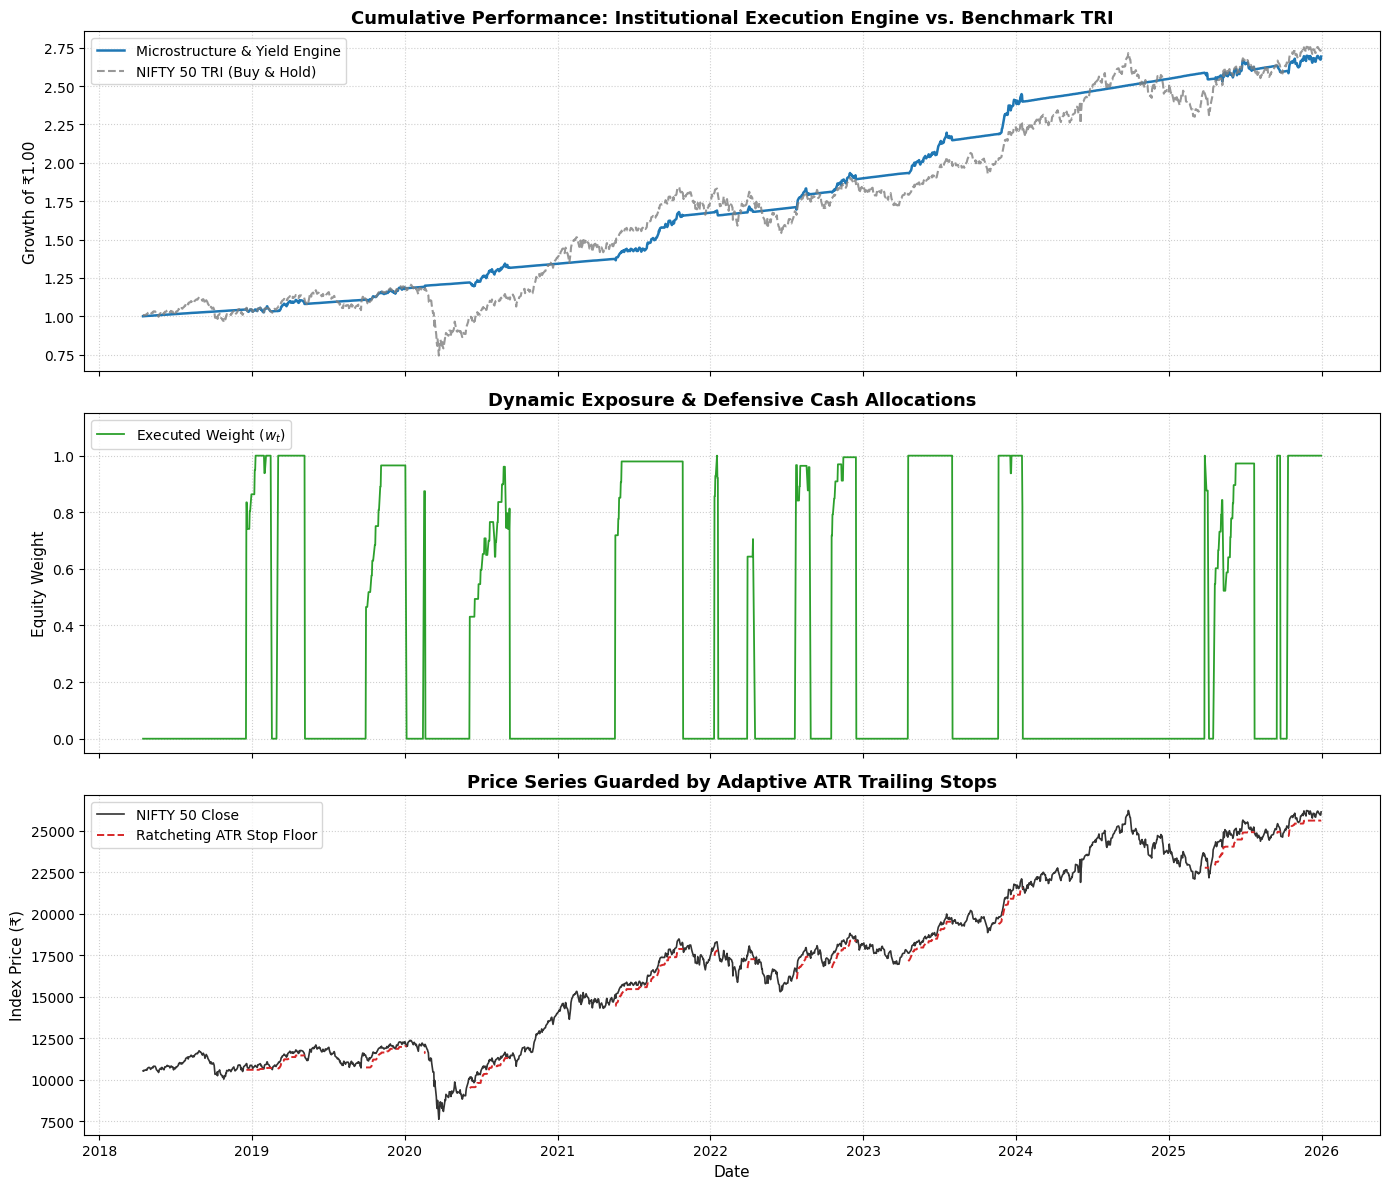

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

# Panel 1: Compounded Equity Curves
axes[0].plot(df.index, df['Strategy_Equity'], label='Microstructure & Yield Engine', color='#1f77b4', linewidth=1.8)
axes[0].plot(df.index, df['Benchmark_Equity'], label='NIFTY 50 TRI (Buy & Hold)', color='#7f7f7f', linestyle='--', alpha=0.8)
axes[0].set_title('Cumulative Performance: Institutional Execution Engine vs. Benchmark TRI', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Growth of ₹1.00', fontsize=11)
axes[0].legend(loc='upper left')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Panel 2: Dynamic Position Allocation
axes[1].plot(df.index, df['Weight'], label='Executed Weight ($w_t$)', color='#2ca02c', linewidth=1.3)
axes[1].set_title('Dynamic Exposure & Defensive Cash Allocations', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Equity Weight', fontsize=11)
axes[1].set_ylim(-0.05, 1.15)
axes[1].legend(loc='upper left')
axes[1].grid(True, linestyle=':', alpha=0.6)

# Panel 3: Price Action with Adaptive Trailing Stop Floor
axes[2].plot(df.index, df['Close'], label='NIFTY 50 Close', color='#333333', linewidth=1.2)
axes[2].plot(df.index, df['Stop_Level'].replace(0.0, np.nan), label='Ratcheting ATR Stop Floor', color='#d62728', linestyle='--', linewidth=1.4)
axes[2].set_title('Price Series Guarded by Adaptive ATR Trailing Stops', fontsize=13, fontweight='bold')
axes[2].set_ylabel('Index Price (₹)', fontsize=11)
axes[2].set_xlabel('Date', fontsize=11)
axes[2].legend(loc='upper left')
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('nifty50_institutional_engine_dashboard.png', dpi=300, bbox_inches='tight')
plt.show()